## Info

* data source: https://www.ebi.ac.uk/chembl/web_components/explore/drug_mechanisms/STATE_ID:MO3G6xgpPVFlKUjNSNR1Hw%3D%3D

## Mechanism of Action

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv('../UniPert/data/processed_CHEMBL_drug_mechnisms.csv', sep=';', low_memory=False)
df = df[df['Smiles'] != 'None']
df.columns

Index(['Parent Molecule ChEMBL ID', 'Parent Molecule Name',
       'Parent Molecule Type', 'Max Phase', 'First Approval', 'USAN Stem',
       'Smiles', 'Mechanism of Action', 'Mechanism Comment',
       'Selectivity Comment', 'Target ChEMBL ID', 'Target Name', 'Action Type',
       'Target Type', 'Target Organism', 'Binding Site Name',
       'Binding Site Comment', 'References', 'Synonyms', 'ATC Codes',
       'Level 4 ATC Codes', 'Level 3 ATC Codes', 'Level 2 ATC Codes',
       'Level 1 ATC Codes', 'Parent Molecule ChEMBL ID.1',
       'Np Likeness Score'],
      dtype='object')

In [35]:
moa_df = df.loc[:, ['Mechanism of Action', 'Smiles']].drop_duplicates().dropna(subset=['Mechanism of Action', 'Smiles'], how='any')
moa_df['Smiles'].value_counts()

Smiles
CNC(=O)c1cc(Oc2ccc(NC(=O)Nc3ccc(Cl)c(C(F)(F)F)c3)c(F)c2)ccn1               15
CCN(CC)CCNC(=O)c1c(C)[nH]c(/C=C2\C(=O)Nc3ccc(F)cc32)c1C                    11
COc1cc2ncnc3c2cc1OCCCCCN(C)Cc1ccc(Br)cc1N3                                  9
Cc1ccc(Nc2nccc(N(C)c3ccc4c(C)n(C)nc4c3)n2)cc1S(N)(=O)=O                     8
O=C(NO)C1(CS(=O)(=O)c2ccc(Oc3ccc(Cl)cc3)cc2)CCOCC1                          7
                                                                           ..
Cc1ccc(O)c(C(=O)N[C@H]2CC[C@@H](NC(=O)c3cc(F)cnc3Oc3ccc(F)c(F)c3)CC2)c1     1
Cc1ccc(Cn2nc(CCCc3ccc(OC(C)(C)C(=O)O)cc3)nc2O)cc1                           1
CCCS(=O)(=O)Nc1ccc(F)c(C(=O)c2c[nH]c3ncc(-c4ccc(Cl)cc4)cc23)c1F             1
O/N=c1\cc(-c2cc3sccc3cn2)oc2ccc(CCCN3CCOCC3)cc12                            1
CC(C)C(=O)O[C@@H](OC(=O)NC[C@H](CC(=O)O)c1ccc(Cl)cc1)C(C)C                  1
Name: count, Length: 2812, dtype: int64

In [49]:
df = df.dropna(subset=['Mechanism of Action', 'Smiles'], how='any')
df = df.loc[:, ['Parent Molecule ChEMBL ID', 'Parent Molecule Name', 'Mechanism of Action', 'Smiles']].drop_duplicates()


In [48]:
top_num = (moa_df['Mechanism of Action'].value_counts()>25).sum()
top_moa = df['Mechanism of Action'].value_counts().index[:top_num].to_list()
df['Mechanism of Action'].value_counts()[:top_num]

Mechanism of Action
Glucocorticoid receptor agonist                                 65
Histamine H1 receptor antagonist                                59
DNA inhibitor                                                   57
Sodium channel alpha subunit blocker                            51
Epidermal growth factor receptor erbB1 inhibitor                47
Cyclooxygenase inhibitor                                        45
GABA-A receptor; anion channel positive allosteric modulator    45
Serotonin 2a (5-HT2a) receptor antagonist                       44
Dopamine D2 receptor antagonist                                 43
Vascular endothelial growth factor receptor inhibitor           40
Beta-2 adrenergic receptor agonist                              36
Tyrosine-protein kinase receptor FLT3 inhibitor                 35
Muscarinic acetylcholine receptor M3 antagonist                 35
MAP kinase p38 alpha inhibitor                                  35
Norepinephrine transporter inhibitor      

## Get drug embeddings

In [ ]:
import sys
unipert_path = '../UniPert'
unipert_data_path = '../UniPert/data'
sys.path.append(unipert_path)

from unipert import UniPert
unipert = UniPert(data_dir=unipert_data_path, 
                  model_hparams = {'save_dir': "../UniPert/current_model"},
                  device = 'cpu')
unipert.load_unipert_reps()

💡 Model have already trained at ../../UniPert/current_model. 
💡 UniPert model hyperparameters settings:
    version: v1
    out_dim: 256
    gnn_type: GCN
    layer_num: 2
    graph_type: weighted_directed
    target_embedder: ESM2
    compound_embedder: ECFP4
    device: cuda:0
    exp_name: unipert_gnn_gs_0717/GCN_2_256
    seed: 2024
    bs: 512
    epochs1: 1000
    epochs2: 1000
    lr1: 0.005
    lr2: 0.005
    wd: 1e-05
    mm: 0.99
    drop_edge_p_1: 0.1
    drop_feat_p_1: 0.3
    drop_edge_p_2: 0.3
    drop_feat_p_2: 0.1
    exp_time: 20240717-113151
    save_dir: /fionafyang/lynnymli/UniPert/saved_models/unipert_gnn_gs_0717/GCN_2_256
Loading model from ../../UniPert/current_model...
💡 Constructing UniPert model...
✅ ESM2 model loaded.
✅ Reference ESM2 embedding file loaded.
✅ ESM2 embedder created.
✅ ECFP4 embedder loaded.
✅ UniPert model constructed.
✅ Pretrained model file loaded.
💡 Building a weighted_directed graph...
✅ Reference target graph prepared.
✅ Referece represen

In [9]:
all_unipert_reps = unipert.encode_chemical_perturbagens_from_smiles(list(df['Smiles']))
len(all_unipert_reps)

✅ Referece representations loaded.


100%|██████████| 258/258 [00:05<00:00, 46.66it/s]


636

In [10]:
unipert_reps = {key: value for key, value in all_unipert_reps.items() if key in list(df['Smiles'])}
len(unipert_reps)

636

In [11]:
ecfp4_reps = {key: value for key, value in unipert.cp_embedder.saved_embs.items() if key in list(df['Smiles'])}
len(ecfp4_reps)

636

## Cal drug-drug similarity

In [ ]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist, squareform
from itertools import combinations
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit import DataStructs

# # Tanimoto sim
def calculate_tanimoto_similarity(sm_i, sm_j):
    mol_i = Chem.MolFromSmiles(sm_i)
    mol_j = Chem.MolFromSmiles(sm_j)
    if mol_i is None or mol_j is None:
        return 0  
    fp_i = AllChem.GetMorganFingerprint(mol_i, 2)
    fp_j = AllChem.GetMorganFingerprint(mol_j, 2)
    return DataStructs.TanimotoSimilarity(fp_i, fp_j)

similarity_list = []

### all compounds

# cal all SMILES's sim
all_smiles = list(df['Smiles'])
all_reps = np.array([unipert_reps[smiles] for smiles in all_smiles])
dist_matrix = pdist(all_reps, metric='cosine')
cosine_similarity_matrix = 1 - squareform(dist_matrix)

# init Tanimoto sim
tanimoto_similarity_matrix = np.zeros((len(all_smiles), len(all_smiles)))

# cal Tanimoto sim
for i, sm_i in enumerate(all_smiles):
    for j, sm_j in enumerate(all_smiles):
        if i < j:  
            tanimoto_similarity_matrix[i, j] = calculate_tanimoto_similarity(sm_i, sm_j)
            tanimoto_similarity_matrix[j, i] = tanimoto_similarity_matrix[i, j]

for i, j in combinations(range(len(all_smiles)), 2):
    similarity_list.append(('Overall', all_smiles[i], all_smiles[j], cosine_similarity_matrix[i, j], tanimoto_similarity_matrix[i, j]))


### group by mechanism of action
grouped = df.groupby('Mechanism of Action')

for group_name, group_df in grouped:
    group_smiles = group_df['Smiles'].tolist()
    group_reps = np.array([unipert_reps[smiles] for smiles in group_smiles])
    group_dist_matrix = pdist(group_reps, metric='cosine')
    group_cosine_similarity_matrix = 1 - squareform(group_dist_matrix)
    
    group_tanimoto_similarity_matrix = np.zeros((len(group_smiles), len(group_smiles)))
    
    for i, sm_i in enumerate(group_smiles):
        for j, sm_j in enumerate(group_smiles):
            if i < j:  
                group_tanimoto_similarity_matrix[i, j] = calculate_tanimoto_similarity(sm_i, sm_j)
                group_tanimoto_similarity_matrix[j, i] = group_tanimoto_similarity_matrix[i, j]

    for i, j in combinations(range(len(group_smiles)), 2):
        similarity_list.append((group_name, group_smiles[i], group_smiles[j], group_cosine_similarity_matrix[i, j], group_tanimoto_similarity_matrix[i, j]))

In [ ]:
similarity_df = pd.DataFrame(similarity_list, columns=['Mechanism of Action', 'Smiles1', 'Smiles2', 'Cosine Similarity', 'Tanimoto Similarity'])
similarity_df.to_csv('../UniPert/results/calculated_moa_drug_similarity_df.csv', index=False)                

## Import similarity

In [ ]:
import pandas as pd
similarity_df = pd.read_csv('../UniPert/results/calculated_moa_drug_similarity_df.csv', low_memory=False)
len(similarity_df)

3978640

In [21]:
avg_cosine_similarity = similarity_df.groupby('Mechanism of Action')['Cosine Similarity'].mean().reset_index()
avg_cosine_similarity = avg_cosine_similarity.rename(columns={'Cosine Similarity': 'Avg Cosine Similarity'}).sort_values(by='Avg Cosine Similarity')

avg_tanimoto_similarity = similarity_df.groupby('Mechanism of Action')['Tanimoto Similarity'].mean().reset_index()
avg_tanimoto_similarity = avg_tanimoto_similarity.rename(columns={'Tanimoto Similarity': 'Avg Tanimoto Similarity'}).sort_values(by='Avg Tanimoto Similarity')

similarity_df = similarity_df.merge(avg_cosine_similarity, on='Mechanism of Action', how='left')
similarity_df = similarity_df.merge(avg_tanimoto_similarity, on='Mechanism of Action', how='left')

top_moas = similarity_df['Mechanism of Action'].value_counts().index[:top_num+1].to_list()
similarity_df = similarity_df.loc[similarity_df['Mechanism of Action'].isin(top_moas)]

rank_moa = list(similarity_df.sort_values(by=['Avg Cosine Similarity'])['Mechanism of Action'].drop_duplicates().values)
rank_moa.remove('Overall')
rank_moa.append('Overall')
rank_moa

['DNA inhibitor',
 'Tyrosine-protein kinase receptor FLT3 inhibitor',
 'Cyclooxygenase inhibitor',
 'Sodium channel alpha subunit blocker',
 'Beta-2 adrenergic receptor agonist',
 'Serotonin 2a (5-HT2a) receptor antagonist',
 'Histamine H1 receptor antagonist',
 'Dopamine D2 receptor antagonist',
 'Vascular endothelial growth factor receptor 2 inhibitor',
 'Vascular endothelial growth factor receptor inhibitor',
 'Epidermal growth factor receptor erbB1 inhibitor',
 'Muscarinic acetylcholine receptor M3 antagonist',
 'Stem cell growth factor receptor inhibitor',
 'Mu opioid receptor agonist',
 'Norepinephrine transporter inhibitor',
 'Serotonin transporter inhibitor',
 'GABA-A receptor; anion channel positive allosteric modulator',
 'Glucocorticoid receptor agonist',
 'Overall']

## Cal Standardized Mean Difference, SMD

In [22]:
import pandas as pd

# cal SMD
def calculate_smd(group_data, overall_data):
    pooled_std = ((group_data.std(ddof=1)**2 * (len(group_data) - 1) + overall_data.std(ddof=1)**2 * (len(overall_data) - 1)) / (len(group_data) + len(overall_data) - 2)) ** 0.5
    smd = (group_data.mean() - overall_data.mean()) / pooled_std
    return smd

smd_results_df = pd.DataFrame()

for similarity_measure in ['Cosine Similarity', 'Tanimoto Similarity']:
    overall_group = similarity_df[similarity_df['Mechanism of Action'] == 'Overall'][similarity_measure]
    smd_results_df.loc['Overall', f'{similarity_measure} SMD'] = 0
    
    for group in similarity_df['Mechanism of Action'].unique():
        if group != 'Overall':
            group_data = similarity_df[similarity_df['Mechanism of Action'] == group][similarity_measure]
            smd = calculate_smd(group_data, overall_group)
            smd_results_df.loc[group, f'{similarity_measure} SMD'] = smd


smd_results_df = smd_results_df.loc[rank_moa, :]
smd_results_df

,Cosine Similarity SMD,Tanimoto Similarity SMD
DNA inhibitor,0.228443,-0.535476
Tyrosine-protein kinase receptor FLT3 inhibitor,1.178067,1.105272
Cyclooxygenase inhibitor,1.244460,2.021923
Sodium channel alpha subunit blocker,1.311520,0.945079
Beta-2 adrenergic receptor agonist,1.463433,2.055448
Serotonin 2a (5-HT2a) receptor antagonist,1.751920,1.704188
Histamine H1 receptor antagonist,1.769789,2.228533
Dopamine D2 receptor antagonist,1.800922,1.625250
Vascular endothelial growth factor receptor 2 inhibitor,1.804039,1.310144
Vascular endothelial growth factor receptor inhibitor,1.816798,1.524058


## Plot

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import fontManager, FontProperties
import seaborn as sns

font_path = "../Helvetica.ttf"
fontManager.addfont(font_path)
prop = FontProperties(fname=font_path)
font_name = prop.get_name()

sns.set_theme(
    style="white",
    context="paper",
    font_scale=1.1,
    rc={
        "axes.linewidth": 0.5,
        "axes.edgecolor": "black",
        "axes.labelsize": 9,
        "axes.titlesize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "legend.frameon": False,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "xtick.major.size": 2,
        "ytick.major.size": 2,
        "figure.dpi": 150,
        "savefig.dpi": 600,
        "axes.facecolor": (0, 0, 0, 0),
    }
)

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font_name]   
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["legend.facecolor"] = "white"

print(f"✅ Loaded custom font: {font_name}")

✅ Loaded custom font: Helvetica


In [26]:
def custom_sort_order(value):
    order = list(rank_moa)
    return order.index(value)
    
similarity_df = similarity_df.sort_values(by='Mechanism of Action', key=lambda x: x.map(custom_sort_order))

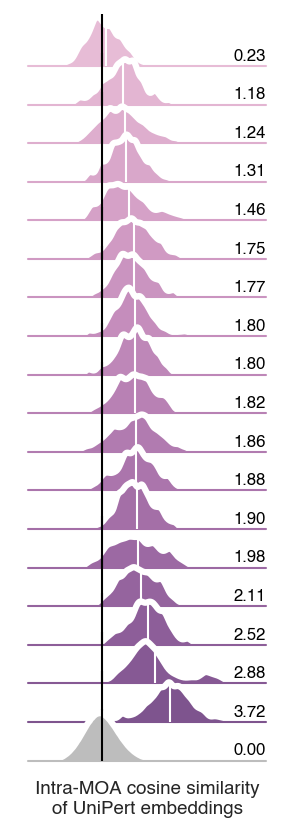

In [27]:
import numpy as np

sim = "Cosine Similarity"
avg_similarity_list = list(similarity_df['Avg '+sim].drop_duplicates().values)

pal = sns.cubehelix_palette(len(rank_moa)+10, rot=.25, light=.8)[:len(rank_moa)]

pal[-1] = "#BDBDBD"
g = sns.FacetGrid(similarity_df, 
                  row='Mechanism of Action', 
                  hue='Mechanism of Action', 
                  aspect=6, 
                  height=.34, 
                  palette=pal,
                  )

g.map(sns.kdeplot, sim,
      bw_adjust=.5, 
      clip_on=False,
      fill=True, 
      alpha=1, 
      linewidth=0,
      )
g.map(sns.kdeplot, sim, 
      clip_on=False, 
      color="w", 
      lw=3, 
      bw_adjust=.5
      )
g.refline(y=0, linewidth=1, linestyle="-", color=None, clip_on=False)


SMD_list = smd_results_df[sim+' SMD'].to_list()
for ax, moa, avg_sim, sim_diff, c in zip(g.axes.flat, rank_moa, avg_similarity_list, SMD_list, pal):
    x_vals, y_vals = ax.lines[0].get_data()
    y_interp = np.interp(avg_sim, x_vals, y_vals)

    ax.vlines(x=avg_sim,
              ymin=0,
              ymax=y_interp,
              color='white',
              linestyle='-',
              linewidth=1,
              label='Class Average')

    ax.text(1, 0.2, 
            f"{sim_diff:.2f}",
            color='black',
            ha="right", 
            va="center", 
            transform=ax.transAxes, 
            fontsize=8
            )
    ax.set_xticklabels(ax.get_xticklabels(), fontsize=6)

g.refline(x=avg_similarity_list[-1], linewidth=1, linestyle='-', color='black')

g.figure.subplots_adjust(hspace=-.25)

g.set_titles(f"")
g.set(yticks=[], ylabel="")
g.set(xlim=(-0.4, 1))

g.set_xlabels(f"Intra-MOA cosine similarity\nof UniPert embeddings", fontsize=9)
g.despine(bottom=True, left=True)

plt.show()

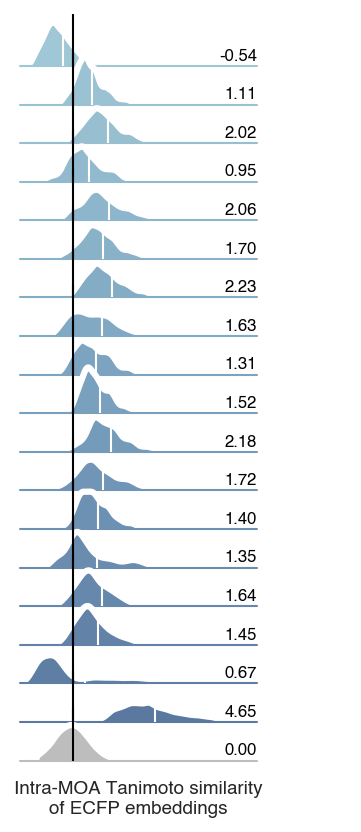

In [28]:
sim = "Tanimoto Similarity"
avg_similarity_list = list(similarity_df['Avg '+sim].drop_duplicates().values)

pal = sns.cubehelix_palette(n_colors=len(rank_moa)+10, rot=-0.2, gamma=0.85, light=0.7, dark=0.2)[:len(rank_moa)]

pal[-1] = "#BDBDBD"
g = sns.FacetGrid(similarity_df, 
                  row='Mechanism of Action', 
                  hue='Mechanism of Action', 
                  aspect=6, 
                  height=.34, 
                  palette=pal,
                  )

g.map(sns.kdeplot, sim,
      bw_adjust=.5, 
      clip_on=False,
      fill=True, 
      alpha=1, 
      linewidth=0,
      )
g.map(sns.kdeplot, sim, 
      clip_on=False, 
      color="w", 
      lw=3, 
      bw_adjust=.5
      )
g.refline(y=0, linewidth=1, linestyle="-", color=None, clip_on=False)


SMD_list = smd_results_df[sim+' SMD'].to_list()
for ax, moa, avg_sim, sim_diff, c in zip(g.axes.flat, rank_moa, avg_similarity_list, SMD_list, pal):
    x_vals, y_vals = ax.lines[0].get_data()
    y_interp = np.interp(avg_sim, x_vals, y_vals)

    ax.vlines(x=avg_sim,
              ymin=0,
              ymax=y_interp,
              color='white',
              linestyle='-',
              linewidth=1,
              label='Class Average')

    ax.text(1, 0.2, 
            f"{sim_diff:.2f}",
            color='black',
            ha="right", 
            va="center", 
            transform=ax.transAxes, 
            fontsize=8
            )
    ax.set_xticklabels(ax.get_xticklabels(), fontsize=6)

g.refline(x=avg_similarity_list[-1], linewidth=1, linestyle='-', color='black')

g.figure.subplots_adjust(hspace=-.25)

g.set_titles(f"")
g.set(yticks=[], ylabel="")
g.set(xlim=(-0.05, 0.75))

g.set_xlabels(f"Intra-MOA Tanimoto similarity\nof ECFP embeddings", fontsize=9)
g.despine(bottom=True, left=True)

plt.show()

In [29]:
moa_df = df.loc[:, ['Mechanism of Action', 'Smiles']].drop_duplicates()
moa_counts = moa_df['Mechanism of Action'].value_counts()
moa_counts.loc['Overall'] = 0

moa_df = pd.DataFrame(list(moa_counts.items()), columns=['MOA', 'Count'])
moa_df = moa_df.set_index('MOA')
moa_df = moa_df.loc[rank_moa, :]
moa_df

,Count
MOA,
DNA inhibitor,52
Tyrosine-protein kinase receptor FLT3 inhibitor,34
Cyclooxygenase inhibitor,44
Sodium channel alpha subunit blocker,48
Beta-2 adrenergic receptor agonist,34
Serotonin 2a (5-HT2a) receptor antagonist,44
Histamine H1 receptor antagonist,59
Dopamine D2 receptor antagonist,43
Vascular endothelial growth factor receptor 2 inhibitor,26


In [30]:
moa = [
    'DNA inhibitor',
    'Tyrosine-protein kinase receptor FLT3 inhibitor',
    'Cyclooxygenase inhibitor',
    'Sodium channel alpha subunit blocker',
    'Beta-2 adrenergic receptor agonist',
    'Serotonin 2a (5-HT2a) receptor antagonist',
    'Histamine H1 receptor antagonist',
    'Dopamine D2 receptor antagonist',
    'Vascular endothelial growth factor receptor 2 inhibitor',
    'Vascular endothelial growth factor receptor inhibitor',
    'Epidermal growth factor receptor erbB1 inhibitor',
    'Muscarinic acetylcholine receptor M3 antagonist',
    'Stem cell growth factor receptor inhibitor',
    'Mu opioid receptor agonist',
    'Norepinephrine transporter inhibitor',
    'Serotonin transporter inhibitor',
    'GABA-A receptor; Anion channel PAM',
    'Glucocorticoid receptor agonist',
    'Overall'
    ]

In [31]:
rank_moa_abbr = [
    "DNA inhibitor", 
    "FLT3 inhibitor", 
    "COX inhibitor", 
    "Na$_{V}$ α-subunit channel blocker", 
    "β$_{2}$AR agonist", 
    "5-HT$_{2A}$ antagonist", 
    "H$_{1}$R antagonist", 
    "D$_{2}$ antagonist", 
    "VEGFR-2 inhibitor", 
    "VEGFR inhibitor", 
    "EGFR inhibitor", 
    "M$_{3}$ antagonist", 
    "SCGFR inhibitor", 
    "MOR agonist", 
    "NET inhibitor", 
    "SERT inhibitor", 
    "GABA$_{A}$R; Anion channel PAM", 
    "GR agonist",
    "All collected drugs"
 ]

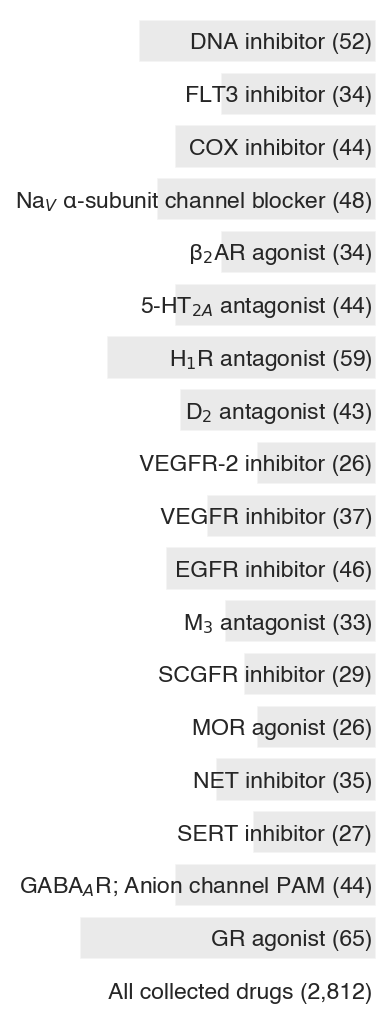

In [ ]:
fig, ax = plt.subplots(figsize=(2.7, 7)) 

sns.barplot(
            data=moa_df[:], 
            y='MOA', 
            x='Count', 
            color='#DCDCDC',
            orient='h', 
            errorbar=None,
            alpha=0.6,
            # order=moa_df['index'],
            ax=ax,
            )

for p, moa in zip(ax.patches, rank_moa_abbr[:]):
    n = p.get_width() if moa != 'All collected drugs' else 2812
    ax.annotate(moa+" ("+format(n, ',.0f')+")", 
                (p.get_x()+3, 0.4+ p.get_y() + p.get_height() / 2.),
                ha = 'right', 
                va = 'center', 
                xytext = (5, 9), 
                textcoords = 'offset points',
                fontsize=11,
                )
    
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.set_yticklabels([], fontsize=9, va='center', ha='right', zorder=1)
ax.set_ylabel('')

ax.set_xlim(ax.get_xlim()[::-1])
ax.set_xticks([])
ax.tick_params(axis='both',    
                which='both',   
                bottom=False,   
                top=False,      
                left=False,     
                right=False)    
ax.set_xlabel('')

plt.tight_layout()  
plt.show()


In [53]:
smd_results_df

,Cosine Similarity SMD,Tanimoto Similarity SMD,Compare
DNA inhibitor,0.228443,-0.535476,0.763919
Tyrosine-protein kinase receptor FLT3 inhibitor,1.178067,1.105272,0.072795
Cyclooxygenase inhibitor,1.244460,2.021923,-0.777464
Sodium channel alpha subunit blocker,1.311520,0.945079,0.366440
Beta-2 adrenergic receptor agonist,1.463433,2.055448,-0.592015
Serotonin 2a (5-HT2a) receptor antagonist,1.751920,1.704188,0.047732
Histamine H1 receptor antagonist,1.769789,2.228533,-0.458744
Dopamine D2 receptor antagonist,1.800922,1.625250,0.175672
Vascular endothelial growth factor receptor 2 inhibitor,1.804039,1.310144,0.493895
Vascular endothelial growth factor receptor inhibitor,1.816798,1.524058,0.292741


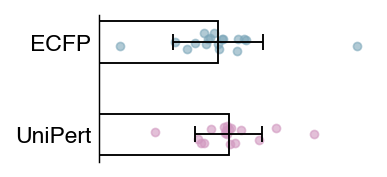

In [56]:
import numpy as np
import matplotlib.pyplot as plt

lw = 0.9
ss = 15

df = smd_results_df[:-1].copy()

cos_vals = df['Cosine Similarity SMD'].values
tan_vals = df['Tanimoto Similarity SMD'].values

means = np.array([cos_vals.mean(), tan_vals.mean()])
errs  = np.array([cos_vals.std(ddof=1), tan_vals.std(ddof=1)])

y = np.array([0, 1])
labels = ['UniPert', 'ECFP']


unipert_bar = "#e5b9d4"
ecfp_bar    = "#a0c7d5"

unipert_scatter = "#d197bf"
ecfp_scatter    = "#7da7ba"


fig, ax = plt.subplots(figsize=(2.7, 1.3))

left = -1   
ax.barh(
    y,
    means - left,
    height=0.45,
    left=left,
    color=[unipert_bar, ecfp_bar],
    linewidth=lw,
    edgecolor='black',
    fill=False,
    zorder=2
)

ax.errorbar(
    means,
    y,
    xerr=errs,
    fmt='none',
    ecolor='black',
    elinewidth=lw,
    capsize=4,
    capthick=lw,
    zorder=3
)

rng = np.random.default_rng(0)
jitter_scale = 0.10

y_cos = np.full_like(cos_vals, y[0], dtype=float) + rng.uniform(-jitter_scale, jitter_scale, size=len(cos_vals))
y_tan = np.full_like(tan_vals, y[1], dtype=float) + rng.uniform(-jitter_scale, jitter_scale, size=len(tan_vals))

ax.scatter(
    cos_vals, y_cos,
    s=ss,
    color=unipert_scatter,
    alpha=0.6,
    zorder=1
)

ax.scatter(
    tan_vals, y_tan,
    s=ss,
    color=ecfp_scatter,
    alpha=0.6,
    zorder=1
)


ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=11)
ax.set_xticks([])
ax.set_xlabel("")
ax.set_xlim(-1, 5)

ax.spines['left'].set_linewidth(lw-0.2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(False)

ax.tick_params(width=lw, length=0, colors='black')

plt.tight_layout()
plt.show()

In [57]:
df.describe()

,Cosine Similarity SMD,Tanimoto Similarity SMD,Compare
count,18.000000,18.000000,18.000000
mean,1.845613,1.613234,0.232379
std,0.728647,0.993094,0.735122
min,0.228443,-0.535476,-0.925700
25%,1.535554,1.319451,-0.226761
50%,1.810419,1.574654,0.234206
75%,1.957927,1.947405,0.499061
max,3.724882,4.650582,2.213680
